In [1]:
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from sklearn.dummy import DummyRegressor
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
model = fetch_california_housing()

X=model.data
y=model.target

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

lr = LinearRegression()

lr.fit(X_train, y_train)

rf=RandomForestRegressor(random_state=42)
rf.fit(X_train,y_train)

lr_pred = lr.predict(X_test)
rf_pred = rf.predict(X_test)


In [3]:
lr_mae=mean_absolute_error(y_test,lr_pred)
lr_rmse=mean_squared_error(y_test,lr_pred)
lr_rs=r2_score(y_test,lr_pred)

print("Linear Regression")
print("MAE:", lr_mae)
print("RMSE:", lr_rmse)
print("R2:", lr_rs)


rf_mae=mean_absolute_error(y_test,rf_pred)
rf_rmse=mean_squared_error(y_test,rf_pred)
rf_rs=r2_score(y_test,rf_pred)

print("\nRandom Forest")
print("MAE:", rf_mae)
print("RMSE:", rf_rmse)
print("R2:", rf_rs)

Linear Regression
MAE: 0.5332001304956989
RMSE: 0.5558915986952425
R2: 0.5757877060324521

Random Forest
MAE: 0.32773108008720936
RMSE: 0.25602182673365537
R2: 0.8046244867176197


In [4]:
from sklearn.dummy import DummyRegressor

baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
baseline_r2 = r2_score(y_test, baseline_pred)

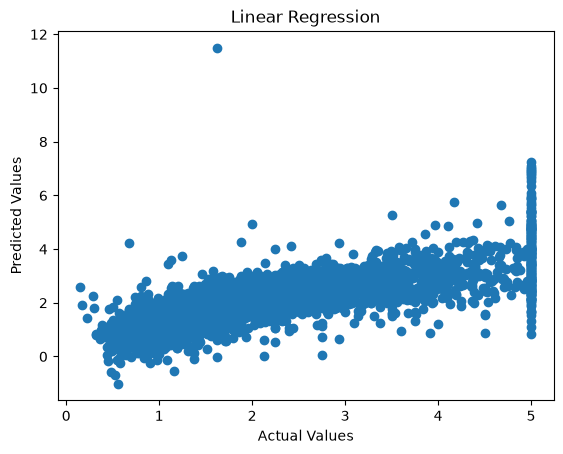

In [5]:
import matplotlib.pyplot as plt

plt.scatter(y_test, lr_pred)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Linear Regression")
plt.show()

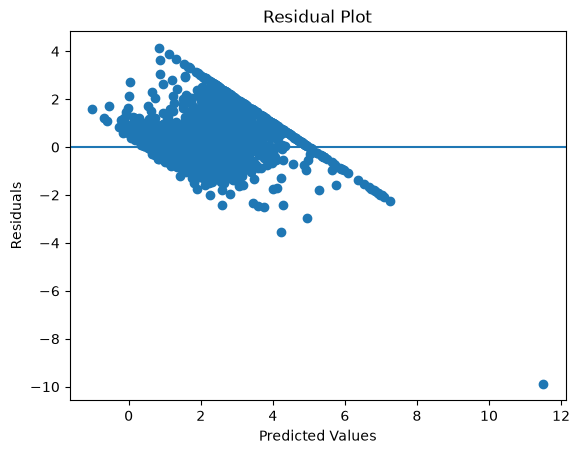

In [6]:
residuals = y_test - lr_pred

plt.scatter(lr_pred, residuals)
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.axhline(y=0)
plt.show()

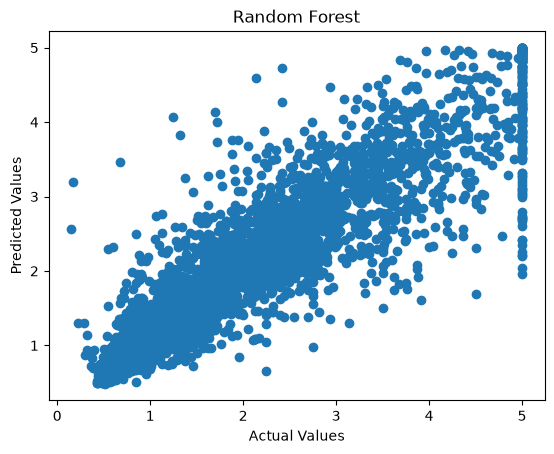

In [ ]:
plt.scatter(y_test, rf_pred)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Random Forest")
plt.show()

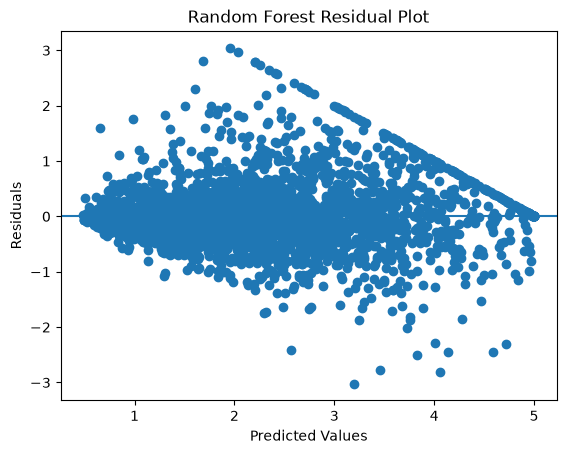

In [8]:
rf_residuals = y_test - rf_pred

plt.scatter(rf_pred, rf_residuals)
plt.axhline(y=0)
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Random Forest Residual Plot")
plt.show()

In [9]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest", "Baseline"],
    "MAE": [lr_mae, rf_mae, baseline_mae],
    "RMSE": [lr_rmse, rf_rmse, baseline_rmse],
    "R2": [lr_rs, rf_rs, baseline_r2]
})

results

,Model,MAE,RMSE,R2
0,Linear Regression,0.533200,0.555892,0.575788
1,Random Forest,0.327731,0.256022,0.804624
2,Baseline,0.906069,1.144856,-0.000219


### Difference between MAE and RMSE and what R-squared of 0.6 means

1. MAE measures the average absolute prediction error.
2. RMSE penalizes larger errors more than MAE.
3. R² = 0.6 means the model explains 60% of the variation in the target.
4. Random Forest performs better than Linear Regression and Baseline in this task.